In [1]:
#Modified from:
#https://amunategui.github.io/reinforcement-learning/index.html
#http://firsttimeprogrammer.blogspot.com/2016/09/getting-ai-smarter-with-q-learning.html
#http://mnemstudio.org/path-finding-q-learning-tutorial.htm
import numpy as np
import pylab as plt

# map cell to cell, add circular cell to goal point
#points_list = [(0,1), (1,5), (5,6), (5,4), (1,2), (2,3), (2,7)]

In [3]:
points_list = [(0,1),(1,2),(1,3),(2,4),(3,5),(3,6)]

In [4]:
goal = 6
#goal = 7

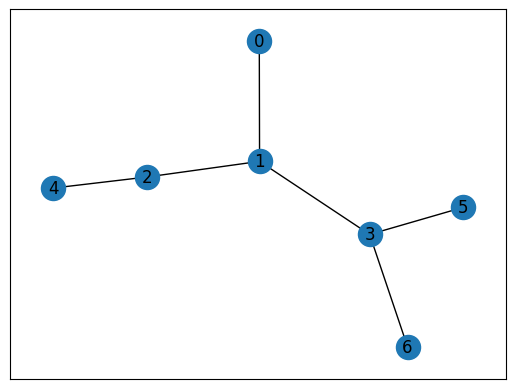

In [5]:
import networkx as nx
G=nx.Graph()
G.add_edges_from(points_list)
pos = nx.spring_layout(G)
nx.draw_networkx_nodes(G,pos)
nx.draw_networkx_edges(G,pos)
nx.draw_networkx_labels(G,pos)
plt.show()

In [6]:
# how many points in graph? x points
MATRIX_SIZE = 7

In [7]:
# create matrix x*y or Value Matrix
R = np.matrix(np.ones(shape=(MATRIX_SIZE, MATRIX_SIZE)))
R *= -1

In [8]:
# assign zeros to paths and 100 to goal-reaching point
for point in points_list:
    print(point)
    if point[1] == goal:
        R[point] = 100
    else:
        R[point] = 0

    if point[0] == goal:
        R[point[::-1]] = 100
    else:
        # reverse of point
        R[point[::-1]]= 0

# add goal point round trip
R[goal,goal]= 100

(0, 1)
(1, 2)
(1, 3)
(2, 4)
(3, 5)
(3, 6)


In [9]:
# display value matrix
R

matrix([[ -1.,   0.,  -1.,  -1.,  -1.,  -1.,  -1.],
        [  0.,  -1.,   0.,   0.,  -1.,  -1.,  -1.],
        [ -1.,   0.,  -1.,  -1.,   0.,  -1.,  -1.],
        [ -1.,   0.,  -1.,  -1.,  -1.,   0., 100.],
        [ -1.,  -1.,   0.,  -1.,  -1.,  -1.,  -1.],
        [ -1.,  -1.,  -1.,   0.,  -1.,  -1.,  -1.],
        [ -1.,  -1.,  -1.,   0.,  -1.,  -1., 100.]])

In [10]:
# Create Q Matrix
Q = np.matrix(np.zeros([MATRIX_SIZE,MATRIX_SIZE]))

#Creates a Q-matrix filled with zeros. This matrix will be updated during learning, with rows representing states and columns representing actions.

# learning parameter/discount factor
gamma = 0.8

initial_state = 1
#This sets the starting point for the agent's learning to state 1.

#Define available_actions Function:
def available_actions(state):
    current_state_row = R[state,]
    av_act = np.where(current_state_row >= 0)[1]
    return av_act

    #Given a state, the above function identifies all possible actions by checking the corresponding row in the reward matrix R.
    #Actions with non-negative values in R are considered "available."

available_act = available_actions(initial_state)

#define a function to Randomly selects an action from the list of available actions, helping the agent explore the environment.

def sample_next_action(available_actions_range):
    next_action = int(np.random.choice(available_act,1))
    return next_action

action = sample_next_action(available_act)

/tmp/ipykernel_3207/1971188334.py:26: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  next_action = int(np.random.choice(available_act,1))


In [11]:
def update(current_state, action, gamma):

  max_index = np.where(Q[action,] == np.max(Q[action,]))[1]

  if max_index.shape[0] > 1:
      max_index = int(np.random.choice(max_index, size = 1))
  else:
      max_index = int(max_index)
  max_value = Q[action, max_index]

  Q[current_state, action] = R[current_state, action] + gamma * max_value
  print('max_value', R[current_state, action] + gamma * max_value)

  if (np.max(Q) > 0):
    return(np.sum(Q/np.max(Q)*100))
  else:
    return (0)

update(initial_state, action, gamma)

max_value 0.0


/tmp/ipykernel_3207/317338325.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  max_index = int(np.random.choice(max_index, size = 1))


0

In [12]:
# Training
scores = []
for i in range(700):
    current_state = np.random.randint(0, int(Q.shape[0]))
    available_act = available_actions(current_state)
    action = sample_next_action(available_act)
    score = update(current_state,action,gamma)
    scores.append(score)
    print ('Score:', str(score))

print("Trained Q matrix:")
print(Q/np.max(Q)*100)

max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 100.0
Score: 100.0
max_value 0.0
Score: 100.0
max_value 0.0
Score: 100.0
max_value 0.0
Score: 100.0
max_value 180.0
Score: 155.55555555555554
max_value 144.0
Score: 235.55555555555554
max_value 144.0
Score: 315.55555555555554
max_value 144.0
Score: 315.55555555555554
max_value 0.0
Score: 315.55555555555554
max_value 144.0
Score: 315.55555555555554
max_value 0.0
Score: 315.55555555555554
max_value 215.2
Score: 317.47211895910783
max_value 0.0
Score: 317.47211895910783
max_value 0.0
Score: 317.47211895910783
max_value 0.0
Score: 317.47211895910783
max_value 144.0
Score: 317.47211895910783
max_value 144.0
Score: 317.47211895910783
max_value

/tmp/ipykernel_3207/1971188334.py:26: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  next_action = int(np.random.choice(available_act,1))
/tmp/ipykernel_3207/317338325.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  max_index = int(np.random.choice(max_index, size = 1))
/tmp/ipykernel_3207/317338325.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  max_index = int(max_index)


Most efficient path:
[0, 1, 3, 6]


/tmp/ipykernel_3207/3851909567.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  next_step_index = int(next_step_index)


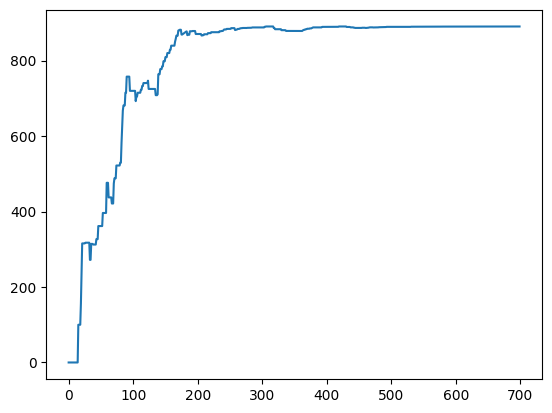

In [13]:
# Testing
current_state = 0
steps = [current_state]

while current_state != 6:

    next_step_index = np.where(Q[current_state,] == np.max(Q[current_state,]))[1]

    if next_step_index.shape[0] > 1:
        next_step_index = int(np.random.choice(next_step_index, size = 1))
    else:
        next_step_index = int(next_step_index)

    steps.append(next_step_index)
    current_state = next_step_index

print("Most efficient path:")
print(steps)

plt.plot(scores)
plt.show()